In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

import copy


## TODO 00: Add GPU support to the script - modify wherever needed (including possibly other places marked with/without 'TODO' )

In [ ]:
# Use CPU/GPU
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
device

device(type='cpu')

#### 1. Config

In [ ]:
# TODO 01: Add the required (but missing here) configuration parameters and their values

config = {
    "dataset": "MNIST",     # options: "MNIST" or "CIFAR10"

    "prototyping": False,
    "prototyping_train_frac": 0.2,

    "num_layers": 3,
    "hidden_sizes": [512, 256, 128],
    "activation": "relu",   # relu, leakyrelu, sigmoid
    'leakyrelu_negative_slope': 0.02,
    "dropout_probs": [0.2, 0.2, 0.0],
    "normalization": "layernorm",   # "none", "batchnorm", "layernorm", "groupnorm"
    "batch_size": 128,
    "epochs": 20,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "optimizer": "adam",    # adam or sgd
    "lr_scheduler": 'OneCycle',   # None, 'OneCycle', 'ReduceOnPlateau'
    "OneCycle": {'max_lr':0.01},
    "patience": 3,
}

#### 2. Dataset

In [ ]:

if config["dataset"] == "MNIST":
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])
    full_train = datasets.MNIST("./data", train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST("./data", train=False, download=True, transform=transform)
    input_size = 28*28
    num_classes = 10

elif config["dataset"] == "CIFAR10":
    # TODO 02: complete this code block so that
    # you can experiment with the CIFAR10 dataset
    #pass # placeholder - remove this
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])
    full_train = datasets.CIFAR10("./data", train=True, download=True, transform=transform)
    test_dataset = datasets.CIFAR10("./data", train=False, download=True, transform=transform)
    input_size = 32*32*3
    num_classes = 10

if config["prototyping"]:
    # work with a fraction of the full dataset for quicker prototyping (e.g. 20%); keep
    # the train:frac ratio to 4:1
    train_size_frac = config["prototyping_train_frac"]

    # TODO 03: complete this code block
    total = int(train_size_frac * len(full_train))
    train_size = int(total * 0.8)
    val_size = total - train_size
    train_val_subset, _ = random_split(full_train, [total, len(full_train) - total])
    train_dataset, val_dataset = random_split(train_val_subset, [train_size, val_size])

else:
    # Split train/val
    train_size = int(0.8 * len(full_train))
    val_size = len(full_train) - train_size
    train_val = full_train

train_dataset, val_dataset = random_split(train_val, [train_size, val_size])



train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=config["batch_size"], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)



#### 3. Model

In [ ]:
# TODO X: You can also make changes to this class to experiment with more diverse MLP configuration (as needed)
class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, num_classes,
                 activation="relu", dropout_probs=None,
                 normalization="none", num_groups=2):
        super().__init__()
        if dropout_probs is None:
            dropout_probs = [0.0]*len(hidden_sizes)

        self.normalization = normalization
        layers = []
        in_dim = input_size

        for i, h in enumerate(hidden_sizes):
            layers.append(nn.Linear(in_dim, h))

            # TODO 04: Add support for batch normalization and layer normalization (separate)
            # --- Normalization ---
            if normalization == "batchnorm":
                #pass
                layers.append(nn.BatchNorm1d(h))
            elif normalization == "layernorm":
                #pass
                layers.append(nn.LayerNorm(h))
            elif normalization == "groupnorm":
                # groups must divide h evenly
                groups = min(num_groups, h)
                layers.append(nn.GroupNorm(groups, h))

            # TODO 05: Add support for relu, leaky relu, and sigmoid activation functions (separate)
            # --- Activation ---
            if activation == "relu":
                layers.append(nn.ReLU())
                #pass
            elif activation == "leakyrelu":
                #layers.append(nn.LeakyReLU(negative_slope=config["leakyrelu_negative_slope"]))
                layers.append(nn.LeakyReLU(negative_slope=config.get("leakyrelu_negative_slope", 0.02)))
                #pass
            elif activation == "sigmoid":
                #pass
                layers.append(nn.Sigmoid())

            # ***********  HINT:
            # Make changes to dropout layer configuration in the Config (if needed) as you
            # experiment with different number of layers

            # --- Dropout ---
            if dropout_probs[i] > 0:
                layers.append(nn.Dropout(dropout_probs[i]))

            in_dim = h

        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # flatten
        return self.net(x)



model = MLP(input_size, config["hidden_sizes"], num_classes,
            activation=config["activation"],
            dropout_probs=config["dropout_probs"])



#### 4. Optimizer & Loss

In [ ]:

# TODO 06: Add support for Adam Optimizer
if config["optimizer"] == "adam":
    optimizer = optim.Adam(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    #pass
else:
    optimizer = optim.SGD(model.parameters(), lr=config["learning_rate"],
                          weight_decay=config["weight_decay"], momentum=0.9)

# TODO 07: use Softmax loss below instead of None (HINT: It is NOT named Softmax loss)
#criterion = None
criterion = nn.CrossEntropyLoss()


#### 5. Training w/ Early Stopping + Checkpoint + Live Plotting

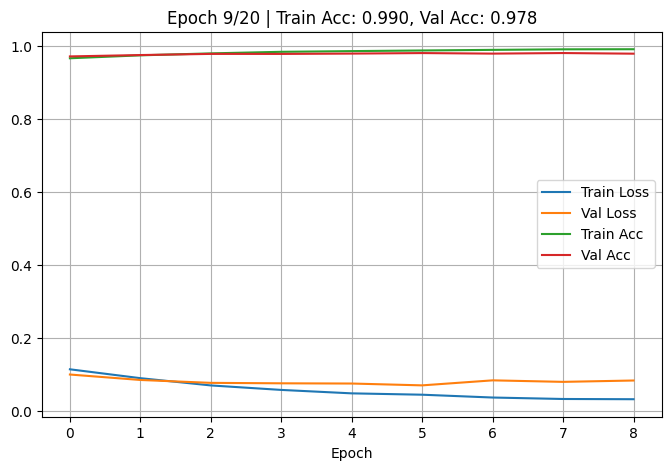

Epoch 1/20 | Train Loss: 0.1132, Train Acc: 0.9652 | Val Loss: 0.0989, Val Acc: 0.9702
Epoch 2/20 | Train Loss: 0.0889, Train Acc: 0.9732 | Val Loss: 0.0839, Val Acc: 0.9740
Epoch 3/20 | Train Loss: 0.0690, Train Acc: 0.9786 | Val Loss: 0.0760, Val Acc: 0.9772
Epoch 4/20 | Train Loss: 0.0567, Train Acc: 0.9829 | Val Loss: 0.0748, Val Acc: 0.9771
Epoch 5/20 | Train Loss: 0.0473, Train Acc: 0.9848 | Val Loss: 0.0742, Val Acc: 0.9780
Epoch 6/20 | Train Loss: 0.0436, Train Acc: 0.9865 | Val Loss: 0.0692, Val Acc: 0.9794
Epoch 7/20 | Train Loss: 0.0358, Train Acc: 0.9882 | Val Loss: 0.0829, Val Acc: 0.9779
Epoch 8/20 | Train Loss: 0.0318, Train Acc: 0.9897 | Val Loss: 0.0788, Val Acc: 0.9795
Epoch 9/20 | Train Loss: 0.0312, Train Acc: 0.9900 | Val Loss: 0.0825, Val Acc: 0.9778
Early stopping.


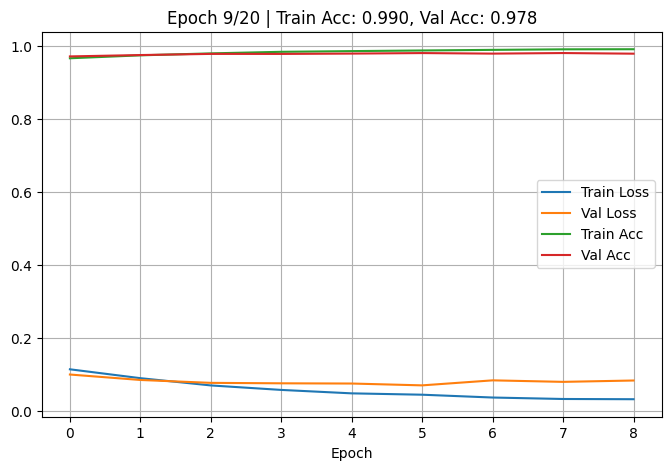

In [ ]:



from IPython.display import clear_output

def train_model(model, train_loader, val_loader, criterion, optimizer, config):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = np.inf
    patience_counter = 0

    # TODO 08: Add support for ReduceOnPlateau and OneCycle LRScheduler (separate) use configuration parameters instead of fixed arguments
    if not config["lr_scheduler"]:
        scheduler = None
    elif config["lr_scheduler"] == "ReduceOnPlateau":
        #pass
        #scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, config["ReduceOnPlateau"])
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, **config.get("ReduceOnPlateau", {}))
    elif config["lr_scheduler"] == "OneCycle":
        #pass
        scheduler = optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=config["OneCycle"]["max_lr"],
            epochs=config["epochs"],
            steps_per_epoch=len(train_loader)
        )
    else:
        scheduler = None

    # Logs
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    # for lazy plotting
    fig, ax = plt.subplots(figsize=(8,5))
    out = display(fig, display_id=True)   # give it a persistent ID

    for epoch in range(config["epochs"]):
        # --- Training ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for X, y in train_loader:
            # TODO 09: Add the missing lines to make training work (with GPU support)
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(X)
            loss = criterion(outputs, y)
            loss.backward()

            optimizer.step()
            running_loss += loss.item() * X.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = correct / total

        # --- Validation ---
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for X, y in val_loader:
                # TODO 10: Add the missing lines to make validation work (with GPU support)
                X, y = X.to(device), y.to(device)
                outputs = model(X)
                loss = criterion(outputs, y)

                val_loss += loss.item() * X.size(0)
                _, preds = torch.max(outputs, 1)
                correct += (preds == y).sum().item()
                total += y.size(0)

        val_loss /= len(val_loader.dataset)
        val_acc = correct / total

        if scheduler:
            if config["lr_scheduler"] == "ReduceOnPlateau":
                scheduler.step(val_loss)
            else:
                scheduler.step()

        # Logging
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # --- Print progress ---
        print(f"Epoch {epoch+1}/{config['epochs']} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")


        # --- Live plot update (persistent) ---
        ax.clear()
        ax.plot(history["train_loss"], label="Train Loss")
        ax.plot(history["val_loss"], label="Val Loss")
        ax.plot(history["train_acc"], label="Train Acc")
        ax.plot(history["val_acc"], label="Val Acc")
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True)
        ax.set_title(f"Epoch {epoch+1}/{config['epochs']} "
                     f"| Train Acc: {train_acc:.3f}, Val Acc: {val_acc:.3f}")

        out.update(fig)   # redraw in the same output cell


        # --- Early stopping + checkpoint ---
        if val_loss < best_loss:
            best_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), "best_model.pth")  # save checkpoint
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["patience"]:
                print("Early stopping.")
                break

    model.load_state_dict(best_model_wts)


    return model, history



model, history = train_model(model, train_loader, val_loader, criterion, optimizer, config)




#### 6. Evaluation

Overall Test Accuracy: 0.9794
Class 0: 0.9878
Class 1: 0.9903
Class 2: 0.9835
Class 3: 0.9822
Class 4: 0.9725
Class 5: 0.9821
Class 6: 0.9614
Class 7: 0.9883
Class 8: 0.9702
Class 9: 0.9732


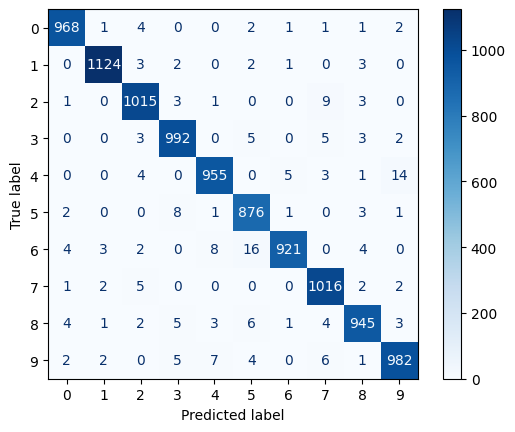

In [ ]:

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X, y in loader:
            # TODO 11: Add the missing lines to make testing work (with GPU support)
            X, y = X.to(device), y.to(device)
            outputs = model(X)

            _, preds = torch.max(outputs, 1)
            correct += (preds == y).sum().item()
            total += y.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

test_acc, preds, labels = evaluate(model, test_loader)
print(f"Overall Test Accuracy: {test_acc:.4f}")

# Per-class accuracy
for i in range(num_classes):
    idx = labels == i
    acc_i = (preds[idx] == labels[idx]).mean()
    print(f"Class {i}: {acc_i:.4f}")

# Confusion Matrix
cm = confusion_matrix(labels, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(num_classes))
disp.plot(cmap=plt.cm.Blues)
plt.show()
